# 06 · Cenários de preço e promoção

A partir das estimativas do F3 no notebook 03, este notebook compara cenários de preço e promoção e mostra quantas observações do treino sustentam cada combinação. A seção 4 compara TPR e display com o mesmo desconto de 20%.

O script `scripts/fit_scenarios.py` reajustou o F3 por REML nas semanas de treino (0 a 103). Em `outputs/runs`, gravou os coeficientes, a covariância conjunta, a tabela de cenários e a conciliação com o notebook 03. As duas versões do notebook leem esse reajuste e a execução do F3 original. As estimativas descrevem associações condicionais nas semanas com vendas registradas.

*Dados: dunnhumby Source Files – Breakfast at the Frat.*

In [1]:
LANG = "pt"

In [2]:
import warnings

import pandas as pd
from IPython.display import display

from retail_multilevel import interpret, viz
from retail_multilevel.i18n import localize_columns, scenario_label, t
from retail_multilevel.runs import load_run

warnings.filterwarnings("ignore", category=FutureWarning)
viz.use_retina()
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:,.3f}".format)
scen = load_run("p2_scenarios", "20261124-220614-acbfe8b9")
fixed = load_run("fixed_effects", "20261124-114202-1fda5a5d")
print(t("data_credit", LANG))
stored = {"p2_scenarios": scen, "fixed_effects": fixed}
display(pd.DataFrame({k: {"run_id": r.run_id, "finished_at": r.metadata["finished_at"]} for k, r in stored.items()}).T)


def localized(df):
    out = df.copy()
    if "scenario" in out:
        out["scenario"] = [scenario_label(x, LANG) for x in out["scenario"]]
    if "term" in out:
        out["term"] = [viz.term_label(x, LANG) for x in out["term"]]
    return localize_columns(out, LANG)

Dados: dunnhumby Source Files – Breakfast at the Frat


,run_id,finished_at
p2_scenarios,20261124-220614-acbfe8b9,2026-11-24T22:08:13.369259
fixed_effects,20261124-114202-1fda5a5d,2026-11-24T11:45:14.599134


As duas execuções lidas estão identificadas acima (identificador e horário de término), e os identificadores são fixados no código, de modo que reexecutar o notebook lê sempre os mesmos artefatos.

## 1. A pergunta e a definição dos cenários

A referência é uma semana regular, sem desconto e sem promoção. Cada cenário estima quanto as vendas modeladas diferem dessa semana e verifica o suporte da combinação no treino. Para um desconto d e indicadores de encarte f, display s e TPR r, a diferença no log das unidades é Δlog = β_desconto · log(1 − d) + β_encarte · f + β_display · s + β_TPR · r. O preço-base e os demais controles ficam constantes. A fórmula `100 × expm1(Δlog)` expressa a variação percentual associada à razão modelada de vendas. O indicador `TPR_ONLY` representa uma redução temporária de preço sem encarte nem display. A tabela mostra como os oito cenários aplicam essa regra.

O notebook 03 registrou os oito cenários antes dos resultados dos contrastes do notebook 05.

In [3]:
design = pd.DataFrame(interpret.DEFAULT_SCENARIOS, columns=["scenario", "discount", "feature", "display", "tpr"])
display(localized(design.assign(discount=design["discount"] * 100)))

,Cenário,Desconto (%),Encarte,Display,TPR
0,Semana regular (sem desconto nem promoção),0.000,0,0,0
1,TPR com 10% de desconto,10.000,0,0,1
2,TPR com 20% de desconto,20.000,0,0,1
3,"Encarte, sem desconto",0.000,1,0,0
4,Encarte com 20% de desconto,20.000,1,0,0
5,"Display, sem desconto",0.000,0,1,0
6,Display com 20% de desconto,20.000,0,1,0
7,Encarte e display com 25% de desconto,25.000,1,1,0


Os intervalos pontuais de 95% usam a covariância conjunta dos coeficientes do F3, ajustado por REML com o `lme4` (Bates et al., 2015). Essa matriz fornece o erro-padrão da combinação linear Δlog e leva em conta as covariâncias entre os coeficientes. A mesma fórmula usada para calcular o efeito percentual retransforma os limites.

## 2. Conciliação com o notebook 03

A tabela verifica se os 14 coeficientes do reajuste que gerou a covariância conjunta coincidem com os coeficientes do F3 gravados no notebook 03.

In [4]:
recon = scen.load_table("reconciliation")
with pd.option_context("display.float_format", "{:,.6f}".format):
    display(localized(recon))
info = scen.load_json("reconciliation")
display(
    localize_columns(
        pd.DataFrame(
            [
                {
                    "nobs": info["nobs"],
                    "max_week": info["max_week"],
                    "messages": info["n_messages"],
                    "coef_max_abs_diff": info["coef_max_abs_diff"],
                    "effect_diff_pp": info["scenario_effect_max_abs_diff_pp"],
                }
            ]
        ),
        LANG,
    )
)

,Termo,Estimativa gravada (notebook 03),Estimativa do reajuste,Diferença absoluta
0,Intercepto,2.961001,2.961001,0.000000
1,Sazonalidade: cosseno 1,0.033744,0.033744,0.000000
2,Sazonalidade: cosseno 2,0.014809,0.014809,0.000000
3,Sazonalidade: cosseno 3,0.010688,0.010688,0.000000
4,Display na loja,0.408673,0.408673,0.000000
5,Encarte,0.497244,0.497244,0.000000
6,"Preço regular, dentro do par (log)",-1.592098,-1.592098,0.000000
7,"Preço regular, média do par (log)",-0.879671,-0.879671,0.000000
8,Profundidade do desconto (log preço / base),-1.685184,-1.685184,0.000000
9,Sazonalidade: seno 1,-0.001711,-0.001711,0.000000


,Observações,Última semana,Mensagens de convergência,Diferença absoluta máxima nos coeficientes,Diferença absoluta máxima nos efeitos (p.p.)
0,347092,103,0,0.000,0.000


O reajuste usa as mesmas 347.092 linhas das semanas 0 a 103, converge sem mensagens e reproduz os 14 coeficientes gravados, com diferença absoluta máxima de 0,0 (a tolerância do script era de 1e-6). Os efeitos pontuais dos cenários também coincidem com os calculados, pela função de cenários do notebook 03, a partir dos coeficientes gravados, com diferença máxima de 0,0 ponto percentual. Os valores e o significado das estimativas são, portanto, os do notebook 03: a mesma combinação linear de coeficientes, na mesma escala. O que se acrescenta é a covariância conjunta, que permite os intervalos que o notebook 03 não podia apresentar.

## 3. Os cenários

A tabela a seguir traz, para cada cenário, o desconto, a variação modelada nas vendas em relação à semana regular e o intervalo pontual de 95%, e, em uma segunda tabela, a diferença em log e o seu erro-padrão. O gráfico mostra os mesmos efeitos ao lado do suporte observado de cada cenário nas linhas de treino.

,Cenário,Desconto (%),Variação modelada nas vendas (%),Inferior 95% (%),Superior 95% (%)
0,Semana regular (sem desconto nem promoção),0.000,0.000,0.000,0.000
1,TPR com 10% de desconto,10.000,14.605,13.910,15.304
2,TPR com 20% de desconto,20.000,39.767,38.998,40.541
3,"Encarte, sem desconto",0.000,64.418,63.046,65.802
4,Encarte com 20% de desconto,20.000,139.476,137.785,141.179
5,"Display, sem desconto",0.000,50.482,49.422,51.549
6,Display com 20% de desconto,20.000,119.177,117.664,120.701
7,Encarte e display com 25% de desconto,25.000,301.772,298.699,304.868


,Cenário,Diferença em log,EP (covariância conjunta)
0,Semana regular (sem desconto nem promoção),0.0000,0.0000
1,TPR com 10% de desconto,0.1363,0.0031
2,TPR com 20% de desconto,0.3348,0.0028
3,"Encarte, sem desconto",0.4972,0.0043
4,Encarte com 20% de desconto,0.8733,0.0036
5,"Display, sem desconto",0.4087,0.0036
6,Display com 20% de desconto,0.7847,0.0035
7,Encarte e display com 25% de desconto,1.3907,0.0039


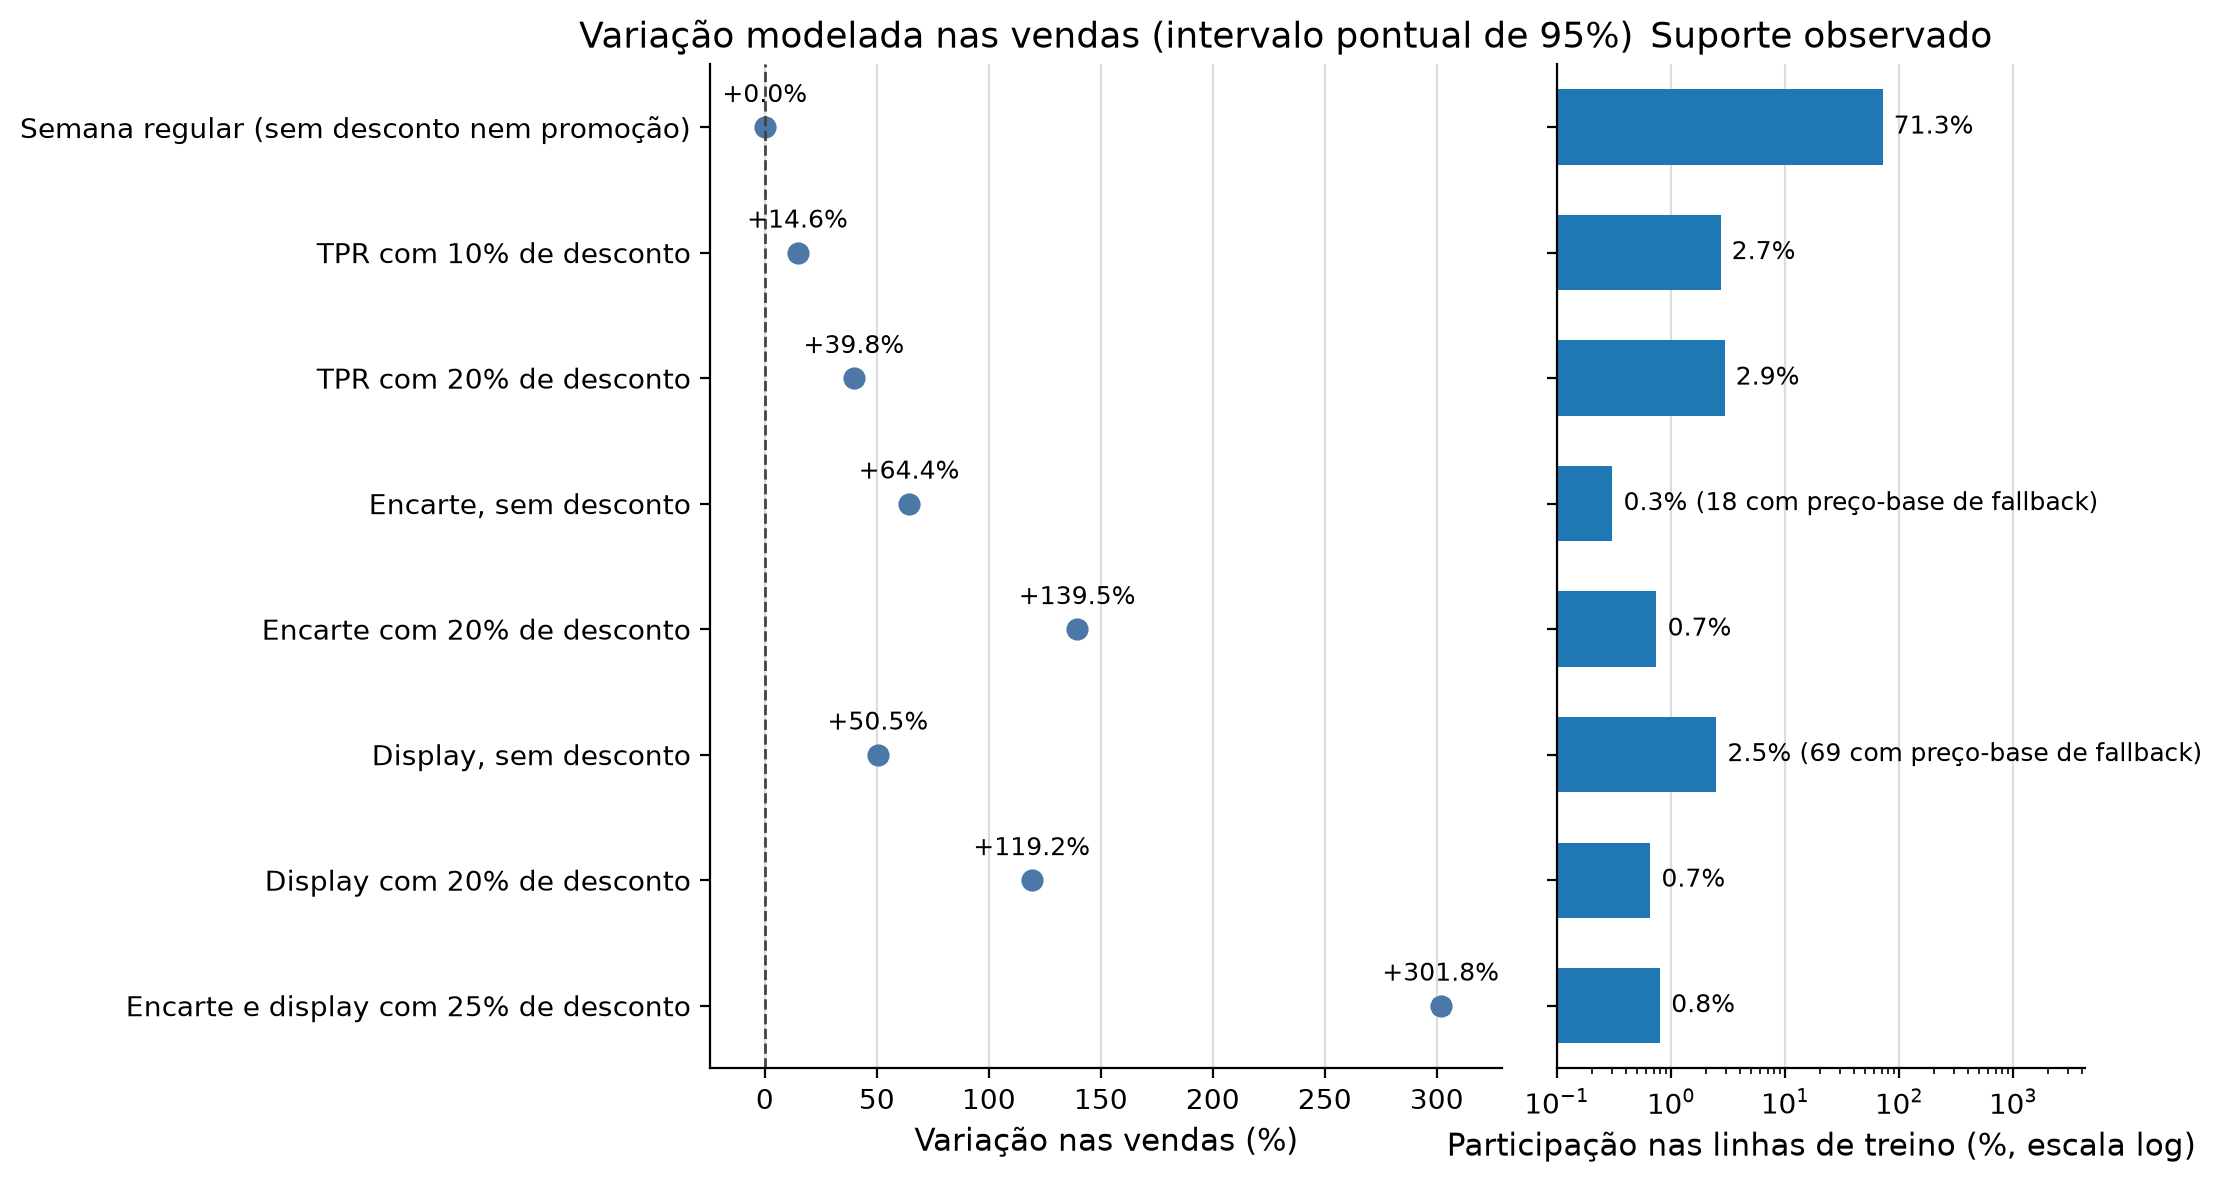

In [5]:
scenarios = scen.load_table("scenarios")
effects = scenarios.assign(discount=scenarios["discount"] * 100)[
    ["scenario", "discount", "effect_pct", "ci_low_pct", "ci_high_pct"]
]
display(localized(effects))
with pd.option_context("display.float_format", "{:,.4f}".format):
    display(localized(scenarios[["scenario", "dlog", "se"]]))
fig = viz.plot_scenario_effects(scenarios, LANG)

A semana regular tem contraste zero, como deve ser. Uma TPR com 10% de desconto está associada a uma variação modelada de +14,6% nas vendas (intervalo de 13,9% a 15,3%), e com 20% de desconto, de +39,8% (de 39,0% a 40,5%). O encarte sem desconto tem +64,4% (de 63,0% a 65,8%), e com 20% de desconto, +139,5% (de 137,8% a 141,2%). O display sem desconto tem +50,5% (de 49,4% a 51,5%), e com 20% de desconto, +119,2% (de 117,7% a 120,7%). O encarte com display e 25% de desconto tem +301,8% (de 298,7% a 304,9%).

Esses valores dependem da forma funcional: a elasticidade é constante em log(1 − d), o desconto e as modalidades são aditivos na escala logarítmica, e não há interação estimada entre encarte e display. O valor do cenário combinado, por exemplo, é o produto dos efeitos estimados em separado. Os intervalos são estreitos porque refletem apenas a variabilidade condicional ao modelo. O notebook 03 mostrou que os erros-padrão agrupados por par e por semana da sensibilidade intrapar ficam de 4,1 a 7,4 vezes os do F3 (Cameron et al., 2011), e portanto os intervalos acima não representam a incerteza completa. Eles também não incorporam o viés possível da seleção de quando e onde cada promoção é aplicada (Villas-Boas & Winer, 1999), que é uma questão de identificação, e não de variabilidade amostral.

## 4. A leitura executiva: TPR com 20% contra display com 20%

A comparação executiva coloca lado a lado os dois cenários de 20% de desconto, que diferem apenas pela modalidade. A razão modelada de vendas do display em relação à TPR é calculada pela diferença dos log-efeitos, com o erro-padrão da combinação linear obtido da covariância conjunta, e retransformada pela exponencial.

In [6]:
executive = scen.load_json("executive")
keys = ["dlog", "se", "effect_pct", "ci_low_pct", "ci_high_pct"]
chosen = pd.DataFrame(
    [{"scenario": executive[s], **{k: executive[e][k] for k in keys}} for s, e in (("a", "effect_a"), ("b", "effect_b"))]
)
ratio = executive["difference_b_minus_a"]
with pd.option_context("display.float_format", "{:,.4f}".format):
    display(localized(chosen))
    display(
        localize_columns(
            pd.DataFrame(
                [
                    {
                        "dlog": ratio["dlog"],
                        "se": ratio["se"],
                        "ratio": ratio["ratio"],
                        "ratio_low": ratio["ratio_low"],
                        "ratio_high": ratio["ratio_high"],
                    }
                ]
            ),
            LANG,
        )
    )

,Cenário,Diferença em log,EP (covariância conjunta),Variação modelada nas vendas (%),Inferior 95% (%),Superior 95% (%)
0,TPR com 20% de desconto,0.3348,0.0028,39.7673,38.9979,40.5410
1,Display com 20% de desconto,0.7847,0.0035,119.1773,117.6636,120.7015


,Diferença em log,EP (covariância conjunta),"Razão modelada de vendas, display vs. TPR","Razão, inferior 95%","Razão, superior 95%"
0,0.4499,0.0043,1.5682,1.5550,1.5815


Com 20% de desconto, a TPR está associada a +39,8% nas vendas modeladas em relação à semana regular (de 39,0% a 40,5%). Para display, a variação é de +119,2% (de 117,7% a 120,7%). A razão modelada de vendas de display em relação à TPR é de 1,568 (intervalo pontual de 1,555 a 1,581), o que corresponde a cerca de 57% a mais no cenário de display. Há observações para os dois cenários. A escolha de quando e onde cada modalidade foi aplicada pode influenciar essa associação condicional.

## 5. O suporte observado

A leitura dos cenários só faz sentido se houver linhas observadas que os realizem. O suporte é contado nas semanas 0 a 103, para a combinação exata de modalidades e com desconto dentro de ± 3 pontos percentuais do valor do cenário. A tabela mostra as linhas, os pares distintos e a participação nas linhas de treino, o mesmo suporte restrito às linhas com preço-base observado (sem `BASE_IMPUTED`), o número de linhas de suporte que vieram do preço-base de fallback (`BASE_PRICE = PRICE`, que zera o desconto da linha) e a indicação de cenário fora do suporte observado.

In [7]:
support = scenarios.assign(
    share=scenarios["share"] * 100, share_observed_base=scenarios["share_observed_base"] * 100
).rename(columns={"share": "share_pct"})[
    [
        "scenario", "n_rows", "n_pairs", "share_pct", "n_rows_observed_base", "n_pairs_observed_base",
        "share_observed_base", "n_rows_fallback", "outside_support",
    ]
]  # fmt: skip
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(localized(support))

,Cenário,Linhas,Pares,Participação nas linhas de treino (%),"Linhas, preço-base observado","Pares, preço-base observado","Participação, preço-base observado (%)",Linhas com preço-base de fallback,Fora do suporte observado
0,Semana regular (sem desconto nem promoção),247331,3858,71.26,247331,3858,71.29,0,False
1,TPR com 10% de desconto,9393,2005,2.71,9393,2005,2.71,0,False
2,TPR com 20% de desconto,10185,2261,2.93,10185,2261,2.94,0,False
3,"Encarte, sem desconto",1057,641,0.30,1038,628,0.30,18,False
4,Encarte com 20% de desconto,2574,1212,0.74,2572,1212,0.74,0,False
5,"Display, sem desconto",8624,1648,2.48,8551,1638,2.46,69,False
6,Display com 20% de desconto,2273,883,0.65,2273,883,0.66,0,False
7,Encarte e display com 25% de desconto,2770,968,0.80,2768,968,0.80,0,False


Todos os cenários têm suporte observado. A semana regular reúne 247.331 linhas (71,26% do treino, 3.858 pares). Cada cenário promocional reúne entre 0,30% e 2,93% das linhas. Com desconto de 10% e 20%, a TPR tem 9.393 linhas (2,71%, 2.005 pares) e 10.185 linhas (2,93%, 2.261 pares), respectivamente. Sem desconto, o encarte tem 1.057 linhas (0,30%, 641 pares) e o display, 8.624 (2,48%, 1.648 pares). Com 20%, o encarte tem 2.574 linhas (0,74%, 1.212 pares) e o display, 2.273 (0,65%, 883 pares). Encarte com display e desconto de 25% tem 2.770 linhas (0,80%, 968 pares). Restringir o suporte às linhas com preço-base observado muda pouco as contagens.

As linhas com preço-base de fallback, que têm desconto zero por construção, aparecem apenas nos cenários sem desconto: 18 linhas no encarte sem desconto (de 1.057) e 69 no display sem desconto (de 8.624). Em relação à tabela do notebook 03, quatro contagens diferem em 1 a 3 linhas (encarte sem desconto, 1.057 contra 1.055; display sem desconto, 8.624 contra 8.622; display com 20%, 2.273 contra 2.272; encarte com display e 25%, 2.770 contra 2.767), porque a borda da janela de ± 3 pontos percentuais passou a ser contada como incluída, com tolerância numérica.

O tratamento de um cenário sem suporte está implementado no código e coberto por testes sintéticos: a linha permanece na tabela, é marcada como fora do suporte observado e não é apresentada como aplicação de negócio. Esse caso não ocorre aqui, e a coluna correspondente continua visível. Não se mostra um recorte do suporte por grupo, porque o F3 usa inclinações comuns a todos os grupos: um recorte por segmento ou por categoria descreveria apenas onde estão os dados, e não efeitos específicos de grupo. O notebook 05 mostrou que as inclinações do desconto variam por nível, de −1,083 a −2,416 entre categorias, de modo que os valores acima descrevem uma associação média, e não a de uma categoria ou de um segmento em particular.

## 6. Limites e escopo

Os cenários estimam razões modeladas de vendas entre condições, usando semanas com vendas registradas e uma forma aditiva em log. O calendário promocional, as rupturas e outros fatores podem influenciar essas associações. A seleção de quando e onde aplicar uma promoção pode enviesar as estimativas, em especial a de preço (Villas-Boas & Winer, 1999). Os intervalos pontuais têm cobertura nominal de 95% sob o modelo. Na sensibilidade intrapar, os erros-padrão agrupados foram muito maiores, o que limita a leitura dos intervalos como medida de incerteza total.

O incremento estimado é de vendas (Blattberg & Neslin, 1989). Uma análise de rentabilidade precisaria considerar custos de promoção, margem, canibalização e retorno sobre o investimento. O suporte observado informa a comparação entre cenários. Prever vendas em condições controladas ou recomendar preços com base em efeitos causais exigiria outro desenho.

In [8]:
slope_test = load_run("discount_slope_lr", "20261125-112223-aa33d3e6")
varcomp = slope_test.load_table("varcomp")
dispersion = varcomp.loc[(varcomp["model"] == "C1") & (varcomp["term"] == "LOG_DISC"), ["group", "sd"]].copy()
dispersion["group"] = dispersion["group"].map({"UPC": t("group_product", LANG), "STORE_NUM": t("group_store", LANG)})
dispersion["common_slope"] = fixed.load_table("fixef").set_index("term").loc["LOG_DISC", "estimate"]
dispersion["sd_over_common"] = dispersion["sd"] / dispersion["common_slope"].abs()
display(localize_columns(dispersion.reset_index(drop=True), LANG))

,Agrupamento,Desvio-padrão,Inclinação comum do F3 (LOG_DISC),DP / |inclinação comum|
0,Loja,0.274,-1.685,0.163
1,Produto,0.884,-1.685,0.524


### Dispersão da inclinação do desconto entre produtos

Os cenários usam a inclinação comum do desconto do F3 (−1,685). Os intervalos estreitos medem a precisão dos contrastes construídos com os coeficientes do F3. No teste complementar do notebook 04 (execução `discount_slope_lr`), o C1 acrescenta ao C0 inclinações aleatórias do desconto por produto e por loja (Gelman & Hill, 2007). No C1, as inclinações variam em torno da própria inclinação fixa do C1, com desvios-padrão estimados de 0,884 entre produtos e 0,274 entre lojas. Como comparação descritiva de escala, esses desvios equivalem a cerca de 52% e 16% do módulo da inclinação do F3, respectivamente. A associação estimada para um produto específico pode diferir substancialmente da associação média dos cenários. Como a execução não gravou a estimativa fixa de `LOG_DISC` do C1, os cálculos de cenário se limitam ao F3, o C0 selecionado pelo protocolo P1.

## Referências

Bates, D., Mächler, M., Bolker, B., & Walker, S. (2015). Fitting linear mixed-effects models using lme4. *Journal of Statistical Software, 67*(1), 1–48. https://doi.org/10.18637/jss.v067.i01

Blattberg, R. C., & Neslin, S. A. (1989). Sales promotion: The long and the short of it. *Marketing Letters, 1*(1), 81–97. https://doi.org/10.1007/BF00436151

Cameron, A. C., Gelbach, J. B., & Miller, D. L. (2011). Robust inference with multiway clustering. *Journal of Business & Economic Statistics, 29*(2), 238–249. https://doi.org/10.1198/jbes.2010.07136

Gelman, A., & Hill, J. (2007). *Data analysis using regression and multilevel/hierarchical models*. Cambridge University Press. https://doi.org/10.1017/CBO9780511790942

Villas-Boas, J. M., & Winer, R. S. (1999). Endogeneity in brand choice models. *Management Science, 45*(10), 1324–1338. https://doi.org/10.1287/mnsc.45.10.1324